=== Top 10 Features Pushing Churn Risk UP ===
                       Feature  Coefficient  Odds_Ratio
   InternetService_Fiber optic       0.6342      1.8855
       Contract_Month-to-month       0.5829      1.7912
                  TotalCharges       0.5363      1.7096
           StreamingMovies_Yes       0.2009      1.2225
               StreamingTV_Yes       0.2005      1.2220
PaymentMethod_Electronic check       0.1979      1.2188
             OnlineSecurity_No       0.1563      1.1692
                TechSupport_No       0.1315      1.1405
             MultipleLines_Yes       0.1046      1.1103
                 SeniorCitizen       0.0534      1.0549

=== Top 10 Features Pushing Churn Risk DOWN ===
                             Feature  Coefficient  Odds_Ratio
                              tenure      -1.2575      0.2844
                   Contract_Two year      -0.7766      0.4600
                 InternetService_DSL      -0.6486      0.5228
                      MonthlyCharges     

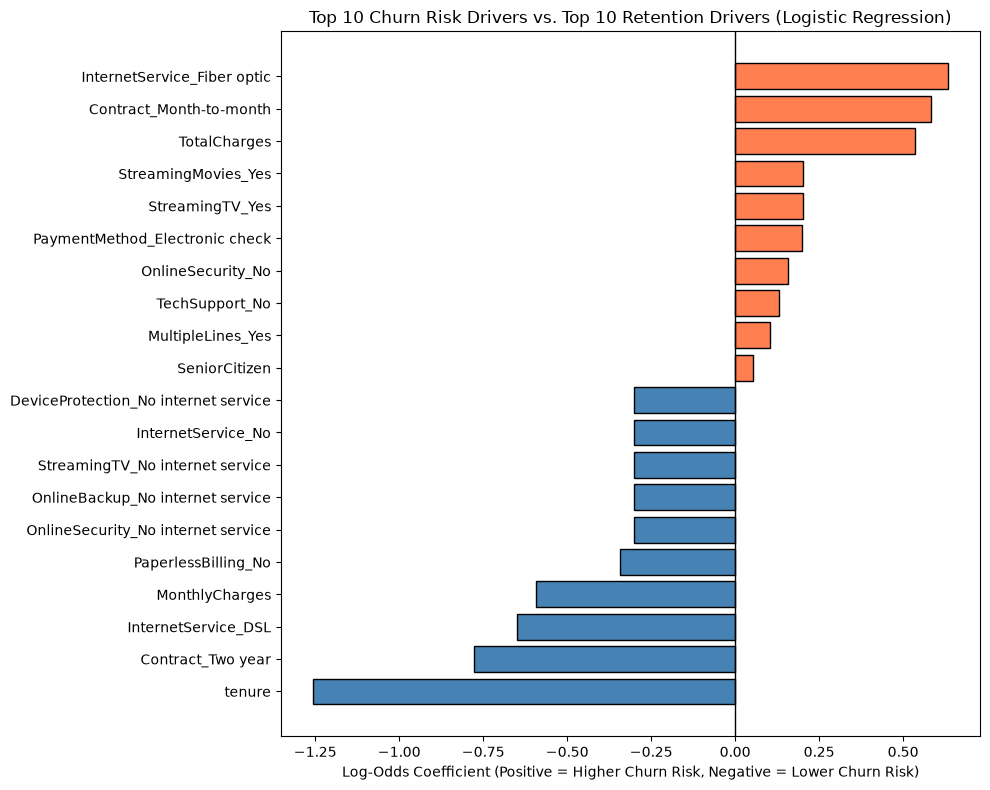

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Load and clean data (adjust file path if needed inside notebooks/)
import sqlite3
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
con = sqlite3.connect(":memory:")
df.to_sql("customers", con, index=False)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"])

# 2. Separate features (X) and binary target (y)
X = df.drop(columns=["customerID", "Churn", "tenure_group"], errors="ignore")
y = (
    df["Churn"].map({"Yes": 1, "No": 0}).astype(int)
    if pd.api.types.is_string_dtype(df["Churn"])
    else df["Churn"].astype(int)
)

# 3. Same stratified 80/20 split as Ticket 3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Build and fit the winning Logistic Regression pipeline on X_train
num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            num_cols,
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            cat_cols,
        ),
    ]
)

logreg_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

logreg_pipe.fit(X_train, y_train)

# 5. Extract feature names and model coefficients
feature_names = logreg_pipe.named_steps["preprocessor"].get_feature_names_out()
# Clean up prefixes like 'num__' and 'cat__' for readability
clean_names = [name.split("__", 1)[-1] for name in feature_names]

coefs = logreg_pipe.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": clean_names,
    "Coefficient": coefs,
    "Odds_Ratio": np.exp(coefs),
}).sort_values(by="Coefficient", ascending=False)

print("=== Top 10 Features Pushing Churn Risk UP ===")
print(coef_df.head(10).to_string(index=False, float_format="%.4f"))

print("\n=== Top 10 Features Pushing Churn Risk DOWN ===")
print(coef_df.tail(10).sort_values(by="Coefficient").to_string(index=False, float_format="%.4f"))

# 6. Plot Top 10 Risk-Increasing vs. Top 10 Risk-Decreasing Features
top_up = coef_df.head(10)
top_down = coef_df.tail(10)
plot_df = pd.concat([top_up, top_down]).sort_values(by="Coefficient", ascending=True)

colors = ["steelblue" if c < 0 else "coral" for c in plot_df["Coefficient"]]

plt.figure(figsize=(10, 8))
plt.barh(plot_df["Feature"], plot_df["Coefficient"], color=colors, edgecolor="black")
plt.axvline(0, color="black", linewidth=1)
plt.title("Top 10 Churn Risk Drivers vs. Top 10 Retention Drivers (Logistic Regression)")
plt.xlabel("Log-Odds Coefficient (Positive = Higher Churn Risk, Negative = Lower Churn Risk)")
plt.tight_layout()
plt.show()


In [3]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].corr()

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000
